In [28]:
!pip -q install huggingface_hub

from huggingface_hub import hf_hub_download
from pathlib import Path

model_path = hf_hub_download(
    repo_id="Sohaaam/Brain_Tumour_ViT",
    filename="vit_brain_tumor_best.pth"
)

print("Model downloaded successfully!")
print("Checkpoint path:", model_path)

Model downloaded successfully!
Checkpoint path: /root/.cache/huggingface/hub/models--Sohaaam--Brain_Tumour_ViT/snapshots/0fa3f76dd43a4dfb3ec60b6eda735a0f902feb20/vit_brain_tumor_best.pth


In [29]:
!pip -q install transformers torchvision pillow

In [30]:
import torch
from transformers import ViTForImageClassification
from huggingface_hub import hf_hub_download

# Public Hugging Face model repository
repo_id = "Sohaaam/Brain_Tumour_ViT"
checkpoint_filename = "vit_brain_tumor_best.pth"

# Download the trained checkpoint (no Google Drive required)
checkpoint_path = hf_hub_download(
    repo_id=repo_id,
    filename=checkpoint_filename,
    repo_type="model"
)

print("Checkpoint downloaded:", checkpoint_path)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Read saved class mapping
class_to_idx = checkpoint["class_to_idx"]
idx_to_class = {v: k for k, v in class_to_idx.items()}

# Recreate model architecture
model_name = checkpoint.get(
    "model_name",
    "google/vit-base-patch16-224-in21k"
)

model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=len(class_to_idx),
    ignore_mismatched_sizes=True
)

# Load your trained weights
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("\nModel loaded successfully!")
print("Classes:", idx_to_class)
print("Checkpoint epoch:", checkpoint.get("epoch", "Not saved"))
print("Validation accuracy:", checkpoint.get("val_accuracy", "Not saved"))
print("Validation F1:", checkpoint.get("val_f1", "Not saved"))

Checkpoint downloaded: /root/.cache/huggingface/hub/models--Sohaaam--Brain_Tumour_ViT/snapshots/0fa3f76dd43a4dfb3ec60b6eda735a0f902feb20/vit_brain_tumor_best.pth
Device: cpu


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model loaded successfully!
Classes: {0: 'glioma', 1: 'meningioma', 2: 'no_tumor', 3: 'pituitary'}
Checkpoint epoch: 3
Validation accuracy: 0.8824839188520535
Validation F1: 0.9112600336898793


In [31]:
class_names = {
    0: "glioma",
    1: "meningioma",
    2: "no_tumor",
    3: "pituitary"
}

Saving 0a5fd3b5e281db1a.jpg to 0a5fd3b5e281db1a (7).jpg


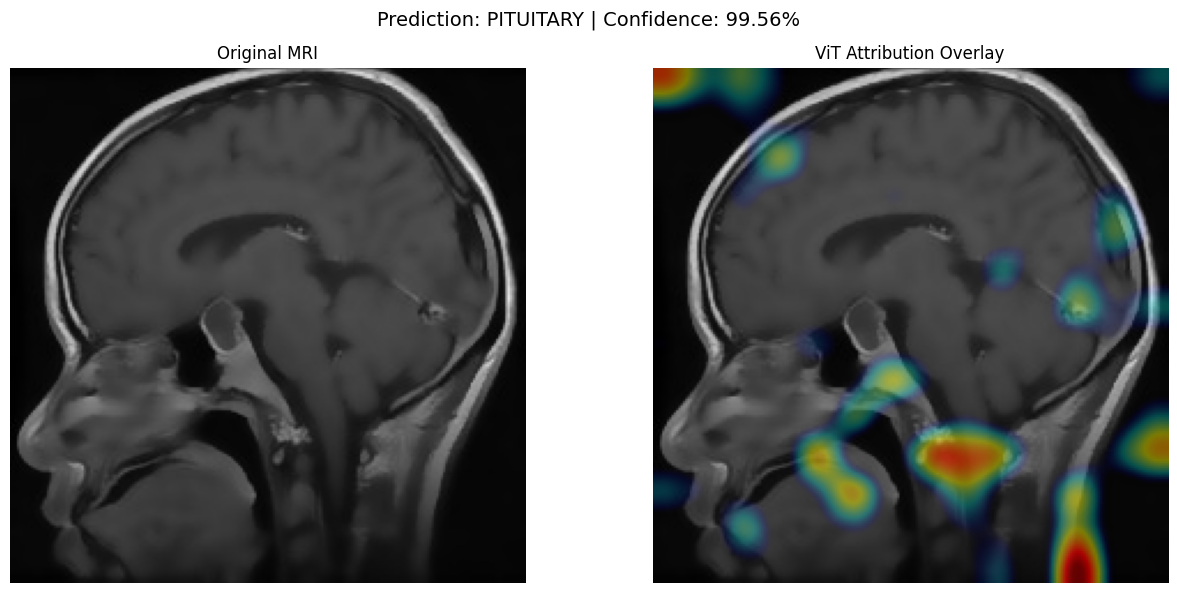

File: 0a5fd3b5e281db1a (7).jpg
Predicted class: PITUITARY
Model confidence: 99.56%

Class-wise probabilities:
GLIOMA         : 0.11%
MENINGIOMA     : 0.25%
NO_TUMOR       : 0.08%
PITUITARY      : 99.56%

Note: Highlighted areas indicate model attribution, not a verified tumour location or boundary.


In [46]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image, UnidentifiedImageError
from io import BytesIO
from google.colab import files

class_names = {
    0: "glioma",
    1: "meningioma",
    2: "no_tumor",
    3: "pituitary"
}


def generate_vit_heatmap(image):
    model.eval()
    image = image.convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)
    captured = {}

    patch_layer = model.vit.embeddings.patch_embeddings

    def capture_features(module, inputs, output):
        output.retain_grad()
        captured["features"] = output

    handle = patch_layer.register_forward_hook(capture_features)

    try:
        model.zero_grad(set_to_none=True)

        with torch.enable_grad():
            outputs = model(input_tensor)
            probabilities = torch.softmax(outputs.logits[0], dim=0)
            predicted_idx = int(probabilities.argmax().item())
            outputs.logits[0, predicted_idx].backward()

        features = captured["features"]
        gradients = features.grad

        if gradients is None:
            raise RuntimeError("Could not calculate attribution gradients.")

        attribution = (features * gradients).sum(dim=-1)[0]
        attribution = torch.relu(attribution)

        if attribution.max().item() < 1e-12:
            attribution = (features * gradients).sum(dim=-1)[0].abs()

        attribution = attribution.detach().float().cpu().numpy()

        grid_size = int(np.sqrt(len(attribution)))
        if grid_size * grid_size != len(attribution):
            raise RuntimeError("Unexpected number of image patches.")

        heatmap = attribution.reshape(grid_size, grid_size)
        heatmap -= heatmap.min()
        heatmap /= heatmap.max() + 1e-8

        heatmap = cv2.resize(
            heatmap.astype(np.float32),
            image.size,
            interpolation=cv2.INTER_CUBIC
        )

        heatmap = np.clip(heatmap, 0, 1)

        return image, heatmap, predicted_idx, probabilities.detach().cpu()

    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)


uploaded = files.upload()

if not uploaded:
    print("No image uploaded.")

for filename, file_bytes in uploaded.items():
    try:
        with Image.open(BytesIO(file_bytes)) as img:
            original = img.convert("RGB")

        original, heatmap, predicted_idx, probabilities = (
            generate_vit_heatmap(original)
        )

        predicted_class = class_names[predicted_idx]
        confidence = probabilities[predicted_idx].item() * 100

        image_rgb = np.asarray(original).astype(np.uint8)

        # Clean and normalize the heatmap
        heatmap = np.nan_to_num(
            heatmap, nan=0.0, posinf=0.0, neginf=0.0
        )
        heatmap = np.clip(heatmap, 0, 1)

        # Suppress weaker attribution values
        threshold = np.percentile(heatmap, 75)
        heatmap_strength = np.clip(
            (heatmap - threshold) / (1.0 - threshold + 1e-8),
            0,
            1
        )

        # Increase contrast in stronger attribution regions
        heatmap_strength = np.power(heatmap_strength, 0.65)

        # Smooth transitions
        heatmap_strength = cv2.GaussianBlur(
            heatmap_strength.astype(np.float32),
            (5, 5),
            0
        )

        # Generate the coloured heatmap
        colour_map = cv2.applyColorMap(
            np.uint8(heatmap_strength * 255),
            cv2.COLORMAP_JET
        )
        colour_map = cv2.cvtColor(
            colour_map,
            cv2.COLOR_BGR2RGB
        )

        # Darker, stronger overlay while retaining MRI structure
        alpha = (heatmap_strength * 0.75)[..., np.newaxis]

        overlay = (
            image_rgb.astype(np.float32) * (1 - alpha)
            + colour_map.astype(np.float32) * alpha
        )
        overlay = np.clip(overlay, 0, 255).astype(np.uint8)

        # Display original MRI and overlay
        fig, axes = plt.subplots(1, 2, figsize=(13, 6))

        axes[0].imshow(image_rgb)
        axes[0].set_title("Original MRI")

        axes[1].imshow(overlay)
        axes[1].set_title("ViT Attribution Overlay")

        for ax in axes:
            ax.axis("off")

        plt.suptitle(
            f"Prediction: {predicted_class.upper()} | "
            f"Confidence: {confidence:.2f}%",
            fontsize=14
        )
        plt.tight_layout()
        plt.show()

        print(f"File: {filename}")
        print(f"Predicted class: {predicted_class.upper()}")
        print(f"Model confidence: {confidence:.2f}%")
        print("\nClass-wise probabilities:")

        for idx, name in class_names.items():
            print(
                f"{name.upper():15s}: "
                f"{probabilities[idx].item() * 100:.2f}%"
            )

        print(
            "\nNote: Highlighted areas indicate model attribution, "
            "not a verified tumour location or boundary."
        )

    except (UnidentifiedImageError, OSError):
        print(f"Cannot read {filename}. Upload a valid image.")

    except Exception as e:
        print(f"Error processing {filename}: {e}")
